노드의 응답과 도구 결과는 `add_messages`로 상태에 병합됩니다. 도구 호출이 있으면 `generate → tools → generate`, 없으면 종료합니다.

In [56]:
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

load_dotenv()
model = ChatOpenAI(
    model="gpt-5.6-luna",
    use_responses_api=True,
)
model.invoke("안녕하세요!")


AIMessage(content=[{'type': 'text', 'text': '안녕하세요! 무엇을 도와드릴까요?', 'annotations': [], 'id': 'msg_047fc95eeeeb2941006acb6de4b55887d0af60de5d1a91aa06', 'phase': 'final_answer'}], additional_kwargs={}, response_metadata={'id': 'resp_047fc95eeeeb2941006acb6de4069c87d0a368e6b769d023ab', 'created_at': 1791716836.0, 'metadata': {}, 'model': 'gpt-5.6-luna', 'object': 'response', 'service_tier': 'default', 'status': 'completed', 'model_provider': 'openai', 'model_name': 'gpt-5.6-luna'}, id='resp_047fc95eeeeb2941006acb6de4069c87d0a368e6b769d023ab', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 9, 'output_tokens': 15, 'total_tokens': 24, 'input_token_details': {'cache_creation': 0, 'cache_read': 0}, 'output_token_details': {'reasoning': 0}})

In [57]:
from typing import Annotated # 타입에 메시지 병합 규칙을 부가합니다.
from typing_extensions import TypedDict # 딕셔너리 형태의 상태 타입을 정의합니다.
from langchain_core.messages import BaseMessage

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

class State(TypedDict):
    """
    State 클래스는 TypedDict를 상속받습니다.

    속성:
        messages (Annotated[list[BaseMessage], add_messages]): 메시지들은 "list" 타입을 가집니다. 
        주석에 있는 'add_messages' 함수는 이 상태 키가 어떻게 업데이트되어야 하는지를 정의합니다.
        (이 경우, 메시지를 덮어쓰는 대신 리스트에 추가합니다)
    """
    messages: Annotated[list[BaseMessage], add_messages]

# StateGraph 클래스를 사용하여 State 타입의 그래프를 생성합니다.
graph_builder = StateGraph(State) 


In [58]:
import sys
from pathlib import Path

# ch12 또는 워크스페이스 루트에서 실행해도 공용 모듈을 찾습니다.
workspace_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "common" / "langchain_tool_functions.py").is_file()),
    None,
)
if workspace_root is None:
    raise FileNotFoundError("common/langchain_tool_functions.py를 찾을 수 없습니다.")
if str(workspace_root) not in sys.path:
    sys.path.insert(0, str(workspace_root))

from common.langchain_tool_functions import get_current_time, get_web_search

# 원래 예제의 두 도구를 공용 파일에서 가져와 사용합니다.
tools = [get_current_time, get_web_search]


In [59]:
tools[0].invoke({"timezone": "Asia/Seoul", "location": "서울"})

Asia/Seoul (서울) 현재시각 2026-10-11 20:07:17 


'Asia/Seoul (서울) 현재시각 2026-10-11 20:07:17 '

In [60]:
tools[1].invoke({"query": "파이썬", "search_period": "m"})

-------- WEB SEARCH --------
파이썬
m


'[{\'title\': \'무료 | 파이썬 입문 | 프로그래머스 스쿨\', \'href\': \'https://school.programmers.co.kr/learn/courses/2\', \'body\': \'파이썬 입문 강의는, 🧑🏻💻👩🏻💻 초보자도 쉽게 시작할 수 있어요. 파이썬이 무엇인지 하나도 몰라도 괜찮아요. 초보자의 눈높이에 맞춰 파이썬 설치부터 함께 하며 누구나 알아들을 수 있게 쉬운 용어로 설명했습니다. ⏰ 하루 15분만 활용하세요. 출퇴근 시간 잠깐, 자기 전에 잠깐 ...\'}, {\'title\': "[광주코딩학원] 요즘 상위권 학생들이 \'파이썬 (Python)\'을 일찍 시작하는 진짜 이유", \'href\': \'https://iocoding.tistory.com/13\', \'body\': "안녕하세요! 프리미엄 코딩 교육의 기준아이오(IO)코딩입니다.수학, 영어 선행만큼이나 요즘 교육 현장에서 가장 뜨거운 화두. 바로 \'코딩\'입니다. 특히 최상위권 학생들의 학습 패턴을 보면 공통적인 특징이 하나 있습니다.중학교 때, 늦어도 고등학교 입학 전에는 파이썬(Python)의 기본기를 탄탄하게 ..."}, {\'title\': \'[260923] 파이썬 데이터 분석\', \'href\': \'https://nbcamp-qaqc-kh.tistory.com/13\', \'body\': \'[금일 진행]- 데이터 분석 파이썬 종합반 강의 5강 수강- 아티클 스터디: 파이썬 초보자가 저지르는 10가지 실수- 파이썬 라이브 세션 진행- 파이썬 알고리즘 코드카타 2~10 진행 [데이터 분석 파이썬 종합반]라이브러리1. pandas데이터 조작과 분석을 위한 라이브러리로, 데이터를 효과적으로 조작하고 ...\'}, {\'title\': \'[고등학생부터, 파이썬] 21. 생성자 (__init__) 와 메서드 (Method)\', \'href\': \'https://kellis.tistory.com/250\', \'body\': \'고등학생부터, 파

In [61]:
for tool in tools:
    print(tool.name, tool)

get_current_time name='get_current_time' description="현재 시각을 반환하는 함수\n\n   Args:\n       timezone (str): 타임존 (예: 'Asia/Seoul') 실제 존재하는 타임존이어야 함\n       location (str): 지역명. 타임존이 모든 지명에 대응되지 않기 때문에 이후 llm 답변 생성에 사용됨" args_schema=<class 'langchain_core.utils.pydantic.get_current_time'> func=<function get_current_time at 0x000002A602060AE0>
get_web_search name='get_web_search' description='웹 검색을 수행하는 함수.\n\nArgs:\n    query: 검색어\n    search_period: 검색 기간' args_schema=<class 'langchain_core.utils.pydantic.get_web_search'> func=<function get_web_search at 0x000002A6035063E0>


In [62]:
model_with_tools = model.bind_tools(tools) # GPT 언어모델에 도구 연결

def generate(state: State):
    """
    주어진 상태를 기반으로 챗봇의 응답 메시지를 생성합니다.

    매개변수:
    state (State): 현재 대화 상태를 나타내는 객체로, 이전 메시지들이 포함되어 있습니다.

    반환값:
    dict: 모델이 생성한 응답 메시지를 포함하는 딕셔너리. 
          형식은 {"messages": [응답 메시지]}입니다.
    """
    return {"messages": [model_with_tools.invoke(state["messages"])]}

graph_builder.add_node("generate", generate)


In [63]:
import json
from langchain_core.messages import ToolMessage

class BasicToolNode:
    """
    도구를 실행하는 노드 클래스입니다. 마지막 AIMessage에서 요청된 도구를 실행합니다.
    Attributes:
        tools_by_name (dict): 도구 이름을 키로 하고 도구 객체를 값으로 가지는 사전입니다.
    Methods:
        __init__(tools: list): 도구 객체들의 리스트를 받아서 초기화합니다.
        __call__(inputs: dict): 입력 메시지를 받아서 도구를 실행하고 결과 메시지를 반환합니다.
    """
    """A node that runs the tools requested in the last AIMessage."""

    def __init__(self, tools: list) -> None:    # ①
        self.tools_by_name = {tool.name: tool for tool in tools}

    def __call__(self, inputs: dict):    # ②
        if messages := inputs.get("messages", []):
            # inputs에 messages가 있으면 messages를 가져오고 없으면 빈 리스트를 가져옵니다.
            message = messages[-1]
        else:
            raise ValueError("No message found in input")
        outputs = []
        for tool_call in message.tool_calls:    # ③
            tool_result = self.tools_by_name[tool_call["name"]].invoke(
                tool_call["args"]
            )
            outputs.append(
                ToolMessage(
                    content=json.dumps(tool_result),
                    name=tool_call["name"],
                    tool_call_id=tool_call["id"],
                )
            )
        return {"messages": outputs}

tool_node = BasicToolNode(tools=tools)
graph_builder.add_node("tools", tool_node)


In [64]:
def route_tools(state: State):
    """
    마지막 메시지에 도구 호출이 있는 경우 ToolNode로 라우팅하고,
    그렇지 않은 경우 끝으로 라우팅하기 위해 conditional_edge에서 사용합니다.
    """
    if isinstance(state, list):
        ai_message = state[-1]
    elif messages := state.get("messages", []):
        ai_message = messages[-1]
    else:
        raise ValueError(f"tool_edge 입력 상태에서 메시지를 찾을 수 없습니다: {state}")
    if hasattr(ai_message, "tool_calls") and len(ai_message.tool_calls) > 0:
        return "tools"
    return END

graph_builder.add_edge(START, "generate")

graph_builder.add_conditional_edges(
    "generate",
    route_tools,
    {"tools": "tools", END: END},
)
# 도구가 호출될 때마다 다음 단계를 결정하기 위해 챗봇으로 돌아갑니다.
graph_builder.add_edge("tools", "generate")
graph = graph_builder.compile()

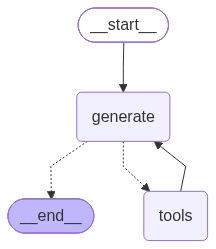

In [65]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [66]:
from langchain_core.messages import AIMessageChunk, HumanMessage

inputs = [HumanMessage(content="지금 서울 몇시야?")]

for msg, metadata in graph.stream(
    {"messages": inputs},
    stream_mode="messages",
):
    if isinstance(msg, AIMessageChunk):
        print(msg.text, end="", flush=True)

print()

Asia/Seoul (서울) 현재시각 2026-10-11 20:07:24 
서울은 지금 **2026년 10월 11일 오후 8시 7분**입니다.


In [67]:
from langchain_core.messages import AIMessageChunk, HumanMessage, SystemMessage

about = "젤다의 전설 시간의 오카리나 관련 이슈"

inputs = [
    SystemMessage(content=(
        "너는 신문기자이다. 웹 검색으로 근거를 확인하고, "
        "확인된 사실과 해석을 구분해 Markdown 형식의 기사를 작성한다."
    )),
    HumanMessage(content=f"""
최근 {about}에 대한 심층 분석 기사를 작성해줘.

- 최근 이슈를 검색하고 핵심 주제를 선정한다.
- 목차를 만들고 필요한 정보를 추가로 검색한다.
- 검색 도구의 search_period는 d, w, m, y 중 하나를 사용한다.
- 최종 기사는 제목, 부제, 리드문, 본문으로 구성한다.
- 출처 링크를 포함하고 확인되지 않은 사실은 단정하지 않는다.
"""),
]

In [68]:
from IPython.display import Markdown, display
from contextlib import redirect_stdout
from io import StringIO
from time import monotonic

answer = ""
last_update = monotonic()
output = display(Markdown("검색 및 답변 생성 중…"), display_id=True)

# 공용 도구 함수의 print 로그는 별도로 보관합니다.
tool_logs = StringIO()

with redirect_stdout(tool_logs):
    for msg, metadata in graph.stream(
        {"messages": inputs},
        stream_mode="messages",
    ):
        if not isinstance(msg, AIMessageChunk):
            continue

        text = msg.text
        if not text:
            continue

        answer += text

        # 너무 잦은 화면 갱신을 피하면서 스트리밍을 유지합니다.
        if monotonic() - last_update >= 0.1:
            output.update(Markdown(answer))
            last_update = monotonic()

output.update(Markdown(answer or "출력된 답변 텍스트가 없습니다."))

# **‘시간의 오카리나’가 다시 시간을 돌린다**
## **닌텐도, 1998년 명작을 스위치 2용으로 재출시… 리메이크는 추억의 복원이 아니라 ‘현대적 재해석’이 될 수 있을까**

### 리드문

닌텐도가 1998년작 **《젤다의 전설 시간의 오카리나》**를 닌텐도 스위치 2용으로 선보인다. 닌텐도는 지난 9월 8일 ‘젤다의 전설 40주년 기념 닌텐도 다이렉트’에서 처음으로 게임플레이를 공개하고, 출시일을 **2026년 11월 5일**로 확정했다. 27년 넘게 게임 역사에서 기준점으로 남아온 작품이 다시 만들어지는 만큼, 이번 발표의 핵심 쟁점은 단순한 신작 공개가 아니다. **원작을 어디까지 바꿔야 리메이크이고, 어디부터는 원작 훼손인가**라는 질문이 다시 떠올랐다.

---

## 목차

1. 공식 확인: 스위치 2판의 출시와 공개 범위  
2. 왜 하필 지금 ‘시간의 오카리나’인가  
3. 리마스터와 리메이크 사이에 선 새 버전  
4. 기대와 우려가 갈리는 이유  
5. 닌텐도가 풀어야 할 세 가지 과제  
6. 결론: 과거를 복원하는 대신, 과거와 대화할 수 있을까  

---

## 1. 공식 확인: 스위치 2판의 출시와 공개 범위

### [확인된 사실]

닌텐도는 2026년 9월 8일 열린 **젤다의 전설 40주년 기념 다이렉트**에서 스위치 2용 《젤다의 전설 시간의 오카리나》의 게임플레이를 공개했다. 닌텐도 공식 발표에 따르면 게임은 **2026년 11월 5일 출시**된다.

- 플랫폼: 닌텐도 스위치 2  
- 출시일: 2026년 11월 5일  
- 최초 공개: 2026년 6월 닌텐도 다이렉트  
- 게임플레이 공개: 2026년 9월 8일 젤다의 전설 40주년 기념 다이렉트  

닌텐도는 이번 작품을 1998년 닌텐도 64판의 단순 이식작으로 소개하지 않았다. 외부 게임 매체들은 공개 영상과 발표 내용을 근거로 이번 버전을 **전면 리메이크에 가까운 신작**으로 분류하고 있다. 다만 닌텐도가 모든 세부 시스템과 콘텐츠 변경 사항을 최종적으로 공개한 것은 아니므로, 현재 유통되는 일부 정보는 공식 확정 내용과 매체·커뮤니티의 분석을 구분해서 볼 필요가 있다.

> **출처**  
> [닌텐도 공식 발표: 젤다의 전설 40주년 기념 행사](https://www.nintendo.com/us/whatsnew/the-legend-of-zelda-40th-anniversary-celebration-revealed-in-new-nintendo-direct-presentation/)  
> [Variety: 2026년 젤다 관련 발표 정리](https://variety.com/2026/gaming/news/gaming-news-roundup-week-september-7-1236855160/)

---

## 2. 왜 하필 지금 ‘시간의 오카리나’인가

### [확인된 사실]

《시간의 오카리나》는 1998년 닌텐도 64로 출시된 작품이다. 3D 그래픽을 기반으로 한 최초의 《젤다의 전설》 본편이며, 3차원 공간에서의 전투와 탐험 구조를 정립한 게임으로 평가받는다.

이 작품은 2011년 닌텐도 3DS용 **《시간의 오카리나 3D》**로 한 차례 공식 리메이크된 바 있다. 이번 스위치 2판이 예정대로 출시되면, 한 작품이 서로 다른 세대의 하드웨어에서 두 차례 공식 리메이크되는 이례적인 사례가 된다.

### [해석]

《시간의 오카리나》가 다시 선택된 이유는 크게 세 가지로 해석할 수 있다.

첫째, **시리즈의 역사적 상징성**이다. 《시간의 오카리나》는 3D 젤다의 출발점이자 이후 《무쥬라의 가면》, 《바람의 지휘봉》, 《황혼의 공주》로 이어지는 설계의 토대가 됐다.

둘째, **40주년이라는 기념비적 시점**이다. 1986년 시작된 《젤다의 전설》 시리즈가 40주년을 맞은 해에 대표작을 다시 내놓는 것은, 닌텐도가 시리즈의 유산을 현재형으로 재정리하려는 움직임으로 볼 수 있다.

셋째, **스위치 2의 초기 라인업 강화**다. 신작이 아닌 유명작의 재해석은 신규 이용자에게는 진입점이 되고, 기존 팬에게는 하드웨어 구매를 자극하는 역할을 한다. 그러나 이는 어디까지나 산업적 해석이며, 닌텐도가 리메이크의 기획 의도를 모두 설명한 것은 아니다.

---

## 3. 리마스터와 리메이크 사이에 선 새 버전

### [확인된 사실]

공개된 영상과 보도에 따르면 스위치 2판은 원작의 그래픽만 개선하는 수준을 넘어, 다음과 같은 변화를 포함하는 것으로 알려졌다.

- 자유로운 카메라 조작  
- 전용 점프 버튼  
- 이동과 수영 조작의 현대화  
- 확장된 일부 공간  
- 캐릭터 대사의 음성 연출 강화  
- 초보 이용자를 위한 안내 기능  

IGN은 공개된 게임플레이를 바탕으로 스위치 2판의 주요 변경점을 분석했고, 여러 매체는 이번 작품이 2011년 3DS판보다 더 큰 폭의 시스템 개편을 포함한다고 보도했다.

다만 **모든 변경 사항이 닌텐도 공식 제품 페이지에서 최종 확정된 것은 아니다.** 특히 세부 지역 구성, 추가 콘텐츠, 음성의 적용 범위, 가격과 패키지 형태 등은 국가별 발표에 따라 달라질 수 있다.

> **출처**  
> [IGN: 스위치 2판 게임플레이 변경점 분석](https://www.ign.com/videos/the-40-biggest-changes-in-the-zelda-ocarina-of-time-gameplay)  
> [Zelda Universe: 닌텐도 64·3DS·스위치 2판 비교](https://www.zeldadungeon.net/zelda-universe-releases-video-comparing-ocarina-of-time-on-the-nintendo-64-3ds-and-switch-2/)

### [해석]

이 변화들은 한 가지 방향을 가리킨다. 닌텐도는 이번 작품을 ‘옛 게임의 고화질판’보다 **오늘날의 조작 감각을 갖춘 새 게임**에 가깝게 만들려는 것으로 보인다.

원작의 카메라는 당시 3D 게임의 기술적 한계 속에서 설계됐다. 플레이어가 카메라를 자유롭게 움직이기보다, 상황에 따라 카메라가 자동으로 조정되는 방식이었다. 이 구조는 당시에는 혁신적이었지만, 자유 시점 조작에 익숙한 오늘날 이용자에게는 답답하게 느껴질 수 있다.

전용 점프 버튼 역시 비슷한 문제를 겨냥한 변화로 해석된다. 원작에서 링크는 지형과 상황에 따라 자동으로 뛰어내리거나 점프했다. 이는 탐험의 규칙이었지만, 현대 이용자에게는 캐릭터의 행동을 직접 통제할 수 없다는 불편으로 받아들여질 가능성이 있다.

문제는 이런 개선이 동시에 **원작의 리듬을 바꾸는 개입**이라는 점이다. 《시간의 오카리나》의 공간 설계와 전투는 제한된 카메라와 조작을 전제로 만들어졌다. 카메라와 이동을 자유롭게 바꾸면 조작은 편해질 수 있지만, 퍼즐의 난이도와 적의 배치, 던전의 동선까지 함께 조정해야 한다.

---

## 4. 기대와 우려가 갈리는 이유

### [확인된 사실]

이번 작품은 1998년 원작, 2011년 3DS판에 이어 세 번째 주요 버전으로 등장한다. 특히 3DS판은 그래픽 개선과 인터페이스 조정, 일부 편의 기능을 더했지만 원작의 구조를 크게 바꾸지는 않았다.

반면 현재 공개된 스위치 2판은 그래픽, 카메라, 이동 방식, 연출 등 여러 요소에서 더 큰 변화가 예고됐다. 때문에 팬 커뮤니티와 게임 매체에서는 이번 작품을 두고 ‘리메이크’와 ‘재창작’ 사이의 성격을 놓고 논의가 이어지고 있다.

### [해석]

팬들의 기대와 우려는 서로 반대처럼 보이지만, 사실 같은 질문에서 출발한다.

> **“이 게임을 다시 만들 때 반드시 남겨야 할 것은 무엇인가?”**

기대하는 쪽은 원작의 세계와 이야기를 유지하면서도 낡은 조작과 화면 구성을 개선할 수 있다는 점에 주목한다. 특히 3D 게임에 익숙하지 않은 신규 이용자에게는 1998년작의 구조가 여전히 불친절할 수 있다. 새로운 카메라와 이동 방식은 이 작품을 현재의 게임으로 연결하는 장치가 될 수 있다.

반대로 우려하는 쪽은 《시간의 오카리나》가 단순히 이야기와 캐릭터만으로 기억되는 작품이 아니라는 점을 강조한다. 제한된 조작, 자동 카메라, 정해진 이동 방식까지 포함한 전체 경험이 원작의 일부였다는 주장이다.

이 논쟁은 그래픽의 향상 여부보다 **게임 디자인의 보존 범위**에 관한 문제다. 원작의 불편함이 기술적 결함인지, 아니면 작품의 문법인지에 따라 평가가 달라질 수 있다.

---

## 5. 닌텐도가 풀어야 할 세 가지 과제

### ① 원작과 리메이크의 경계를 설명해야 한다

닌텐도는 이번 작품이 원작을 얼마나 충실하게 재현하고, 어느 지점에서 새롭게 해석했는지 명확히 설명할 필요가 있다.

단순히 “새롭게 만들었다”고 홍보하는 것만으로는 부족하다. 팬들이 궁금해하는 것은 다음과 같은 구체적인 내용이다.

- 던전 구조가 유지되는가  
- 퍼즐의 정답과 진행 순서가 달라지는가  
- 시간 이동 시스템의 규칙이 바뀌는가  
- 새로운 지역과 퀘스트가 추가되는가  
- 원작의 불편한 요소를 선택적으로 유지할 수 있는가  

이 정보가 충분히 공개되지 않으면, 이용자들은 공개 영상과 유출 정보에 의존하게 된다. 이는 기대를 키우는 동시에 잘못된 추측을 확산시킬 수 있다.

### ② 신규 이용자와 기존 팬을 동시에 설득해야 한다

《시간의 오카리나》는 게임 역사에 익숙한 팬에게는 이미 여러 차례 소비된 작품이다. 닌텐도 64판, 게임큐브 이식판, 가상 콘솔, 3DS판을 거친 이용자도 적지 않다.

따라서 이번 버전이 단순히 “더 선명한 《시간의 오카리나》”에 머문다면 기존 이용자에게 구매 동기를 제공하기 어렵다. 반대로 변화를 지나치게 확대하면 원작 팬의 반발을 부를 수 있다.

가장 현실적인 해법은 원작의 흐름을 유지하면서도 조작과 접근성을 개선하는 것이다. 여기에 새로운 지역이나 선택형 콘텐츠가 추가된다면, 기존 이용자에게도 재플레이의 이유를 제공할 수 있다. 다만 현재까지 닌텐도가 공개한 내용만으로는 이러한 추가 콘텐츠의 구체적 범위를 단정할 수 없다.

### ③ 스위치 2 독점의 의미를 분명히 해야 한다

이번 작품은 스위치 2를 대표하는 타이틀로 기능할 가능성이 크다. 그렇다면 닌텐도는 새 하드웨어가 제공하는 기술적 이점을 단순한 해상도 향상 이상으로 보여줘야 한다.

자유로운 카메라, 개선된 조작, 더 넓은 공간이 실제 게임 경험을 어떻게 바꾸는지 설득하지 못하면, 이용자들은 이번 버전을 새 콘솔을 위한 재판매로 받아들일 수 있다.

반대로 스위치 2의 성능을 활용하면서도 원작 특유의 밀도와 속도감을 보존한다면, 이번 리메이크는 과거의 명성을 이용하는 상품을 넘어 3D 젤다의 기원을 현재에 맞게 번역한 사례가 될 수 있다.

---

## 6. 결론: 과거를 복원하는 대신, 과거와 대화할 수 있을까

### [확인된 사실]

닌텐도는 스위치 2용 《젤다의 전설 시간의 오카리나》의 게임플레이를 공개했으며, 출시일을 **2026년 11월 5일**로 발표했다. 공개 영상과 주요 보도에서는 원작보다 큰 폭의 그래픽·조작·연출 변화가 예고됐다.

### [해석]

이번 작품의 성패는 그래픽 수준이나 원작 재현율만으로 결정되지 않을 가능성이 크다. 더 중요한 것은 닌텐도가 《시간의 오카리나》를 어떤 작품으로 정의하느냐이다.

1998년의 《시간의 오카리나》는 3D 게임의 가능성을 확장한 작품이었다. 2026년의 리메이크가 의미 있으려면, 그 혁신을 단순히 복제하는 데 그치지 않고 오늘날의 플레이어에게 다시 이해시켜야 한다.

그러나 재해석은 늘 손실을 동반한다. 원작의 불편함을 제거하는 순간, 당시의 설계 의도도 일부 사라질 수 있다. 결국 이번 리메이크가 해결해야 할 과제는 “얼마나 많이 바꿀 것인가”가 아니다.

**무엇을 바꾸어도 《시간의 오카리나》로 남을 수 있는가.**

이 질문에 대한 답은 출시일 이후 플레이어들의 경험을 통해 판가름날 것이다.

---

## 출처

- [Nintendo — The Legend of Zelda 40th Anniversary Celebration](https://www.nintendo.com/us/whatsnew/the-legend-of-zelda-40th-anniversary-celebration-revealed-in-new-nintendo-direct-presentation/)  
- [IGN — The 40 Biggest Changes in the Zelda: Ocarina of Time Gameplay](https://www.ign.com/videos/the-40-biggest-changes-in-the-zelda-ocarina-of-time-gameplay)  
- [Zelda Dungeon — 닌텐도 64·3DS·스위치 2판 비교](https://www.zeldadungeon.net/zelda-universe-releases-video-comparing-ocarina-of-time-on-the-nintendo-64-3ds-and-switch-2/)  
- [Variety — 2026년 게임업계 주요 발표](https://variety.com/2026/gaming/news/gaming-news-roundup-week-september-7-1236855160/)  

*기사 작성 기준: 2026년 10월 11일. 닌텐도가 공식적으로 공개한 내용과 외부 매체의 분석·추정을 구분했으며, 세부 시스템과 추가 콘텐츠는 향후 공식 발표에 따라 달라질 수 있습니다.*

In [69]:
print(tool_logs.getvalue())

-------- WEB SEARCH --------
The Legend of Zelda Ocarina of Time recent news issue 2025 2026 Nintendo
m
-------- WEB SEARCH --------
젤다의 전설 시간의 오카리나 최근 이슈 2025 2026
m
-------- WEB SEARCH --------
Ocarina of Time PC port Ship of Harkinian recent 2025 issue
y
웹 검색 오류: No results found.
Asia/Seoul (대한민국) 현재시각 2026-10-11 20:07:42 
-------- WEB SEARCH --------
site:nintendo.com The Legend of Zelda Ocarina of Time Switch 2 November 5 2026 official
m
-------- WEB SEARCH --------
Nintendo Ocarina of Time remake Switch 2 September 2026 announcement
m
웹 검색 오류: No results found.
-------- WEB SEARCH --------
site:nintendo.com "Ocarina of Time" "Switch 2"
m
웹 검색 오류: No results found.
-------- WEB SEARCH --------
Ocarina of Time remake Switch 2 reactions features 2026
m
웹 검색 오류: No results found.
-------- WEB SEARCH --------
Zelda Ocarina of Time recent controversy fan project 2026
y
웹 검색 오류: No results found.
-------- WEB SEARCH --------
Ocarina of Time decompilation fan project legal Nintendo 2025

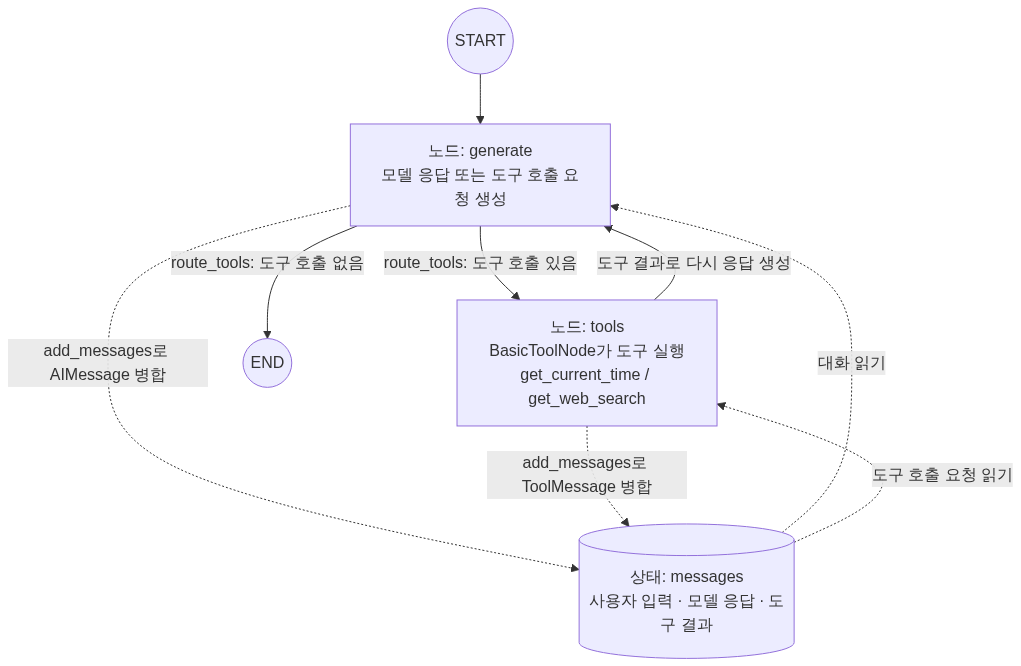

In [71]:
from IPython.display import Image, display
from langchain_core.runnables.graph_mermaid import draw_mermaid_png

mermaid_code = """
flowchart TD
    START((START)) --> GENERATE["노드: generate<br/>모델 응답 또는 도구 호출 요청 생성"]

    GENERATE -->|"route_tools: 도구 호출 있음"| TOOLS["노드: tools<br/>BasicToolNode가 도구 실행<br/>get_current_time / get_web_search"]
    TOOLS -->|"도구 결과로 다시 응답 생성"| GENERATE
    GENERATE -->|"route_tools: 도구 호출 없음"| END((END))

    STATE[("상태: messages<br/>사용자 입력 · 모델 응답 · 도구 결과")]
    STATE -.->|"대화 읽기"| GENERATE
    GENERATE -.->|"add_messages로 AIMessage 병합"| STATE
    STATE -.->|"도구 호출 요청 읽기"| TOOLS
    TOOLS -.->|"add_messages로 ToolMessage 병합"| STATE
"""

display(Image(data=draw_mermaid_png(mermaid_code)))